In [12]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        respath = os.path.join(result_dir, 'validation', dataset.path + '.csv')
        if os.path.exists(respath):
            res = pd.read_csv(respath)
            dataset_ = dataset.drop(labels=[ # `labels` cause `dataset` is Series
                'directory', 'path', 'adapter']) # drop some cols to save space
            res = res.assign(**dataset_)
            chunks.append(res)
valdata = pd.concat(chunks)
del chunks
print('valdata successfully collected.')

100%|██████████| 1828/1828 [00:01<00:00, 1656.68it/s]
valdata successfully collected.


In [15]:
valdata.groupby('validation_method').groups

{'GaussianNB': Int64Index([280, 281, 282, 283, 284, 285, 286, 287, 288, 289,
             ...
             470, 471, 472, 473, 474, 475, 476, 477, 478, 479],
            dtype='int64', length=5825),
 'KNN_5Fold': Int64Index([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,
             ...
             230, 231, 232, 233, 234, 235, 236, 237, 238, 239],
            dtype='int64', length=5825),
 'SVM': Int64Index([840, 841, 842, 843, 844, 845, 846, 847, 848, 849,
             ...
             950, 951, 952, 953, 954, 955, 956, 957, 958, 959],
            dtype='int64', length=5825),
 'XGBoost': Int64Index([560, 561, 562, 563, 564, 565, 566, 567, 568, 569,
             ...
             710, 711, 712, 713, 714, 715, 716, 717, 718, 719],
            dtype='int64', length=5825)}

In [167]:
valdata_ = valdata.copy()
valdata_ = valdata[valdata['name'] == '3-way Epistasis (GAMETES)']
# re-map validation method names
rms = {
    'KNN_5Fold': '1-NN (5-fold CV)',
    'GaussianNB': 'Gaussian Naïve Bayes (5-fold CV)',
    'XGBoost': 'XGBoost (5-fold CV)',
    'SVM': 'SVM (5-fold CV)'
}
valdata_['validation_method'] = valdata_['validation_method'].map(rms.get)

# average over folds
valdata_ = valdata_.groupby(['validation_method', 'description', 'ranking_method', 'replica_no', 'n_features'])\
    .agg({'score': 'mean'})\
    .reset_index()

# add replica count per n_features point
def add_count(group):
    # group['count'] = len(group['replica_no'].unique())
    # return group
    count = group['replica_no'].unique()
    avg = group['score'].mean()
    return pd.Series({
        'replica count': count,
        'score': avg
        # 'score': np.repeat(avg, repeats=len(count))
    })
valdata_ = valdata_.groupby(['description', 'validation_method', 'ranking_method', 'n_features'])\
    .apply(add_count)\
    .explode('replica count')\
    .reset_index()
valdata_['score'] = valdata_['score'].astype(float)
valdata_['replica count'] = valdata_['replica count'].astype(int)
valdata_

,description,validation_method,ranking_method,n_features,replica count,score
0,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",1-NN (5-fold CV),ExtraTrees,1,1,0.500417
1,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",1-NN (5-fold CV),ExtraTrees,1,10,0.500417
2,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",1-NN (5-fold CV),ExtraTrees,1,11,0.500417
3,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",1-NN (5-fold CV),ExtraTrees,1,12,0.500417
4,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",1-NN (5-fold CV),ExtraTrees,1,13,0.500417
...,...,...,...,...,...,...
4655,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",XGBoost (5-fold CV),RFE w/XGBoost,20,5,0.575744
4656,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",XGBoost (5-fold CV),RFE w/XGBoost,20,6,0.575744
4657,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",XGBoost (5-fold CV),RFE w/XGBoost,20,7,0.575744
4658,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...",XGBoost (5-fold CV),RFE w/XGBoost,20,8,0.575744


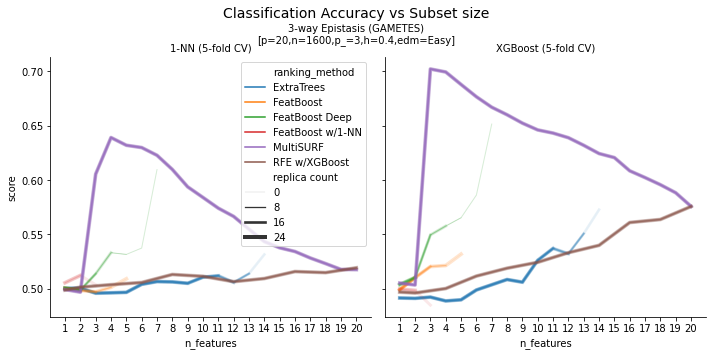

In [205]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
g = sns.relplot(data=valdata_[\
        (valdata_['validation_method'] == '1-NN (5-fold CV)') |\
        (valdata_['validation_method'] == 'XGBoost (5-fold CV)')],
    x='n_features', y='score', hue='ranking_method',
    col='validation_method', col_wrap=2, kind='line',
    # estimator=None, units='replica_no',
    size='replica count', sizes=(.10, 4.0),
    alpha=0.10,
    facet_kws={'legend_out': False}
    )
plt.xticks(np.arange(1, 20+1, 1.0))
g.set_titles("{col_name}")
plt.suptitle('Classification Accuracy vs Subset size', size=14)
plt.figtext(.5, .88,'3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]',\
    fontsize=10, ha='center')
plt.subplots_adjust(top=.84)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_val_knnxgb.svg')

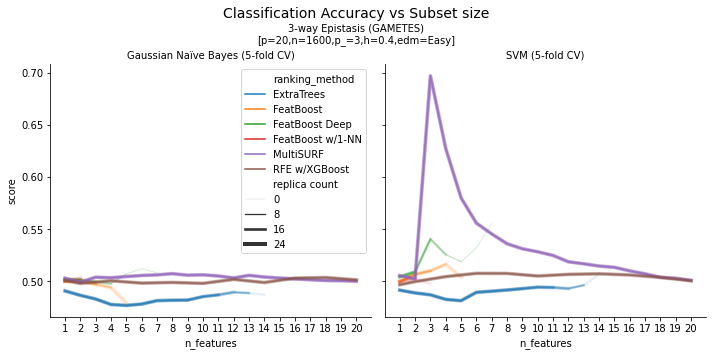

In [207]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
g = sns.relplot(data=valdata_[\
        (valdata_['validation_method'] == 'SVM (5-fold CV)') |\
        (valdata_['validation_method'] == 'Gaussian Naïve Bayes (5-fold CV)')],
    x='n_features', y='score', hue='ranking_method',
    col='validation_method', col_wrap=2, kind='line',
    # estimator=None, units='replica_no',
    size='replica count', sizes=(.10, 4.0),
    alpha=0.10,
    facet_kws={'legend_out': False}
    )
plt.xticks(np.arange(1, 20+1, 1.0))
g.set_titles("{col_name}")
plt.suptitle('Classification Accuracy vs Subset size', size=14)
plt.figtext(.5, .88,'3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]',\
    fontsize=10, ha='center')
plt.subplots_adjust(top=.82)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_val_svmgnb.svg')